# Two-Hand Static Phrase Recognition
Based on the single-hand letter model. Captures **both hands** per frame as a single 128-feature vector (left hand 63 + handedness + right hand 63 + handedness). Missing hands are zero-padded to keep input size fixed.

In [6]:
!pip install opencv-python mediapipe==0.10.14 matplotlib seaborn tensorflow scikit-learn tensorflowjs ipywidgets


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [8]:
import cv2
import mediapipe as mp
import numpy as np
import os
from time import time


# Data Collection

Each sample captures **both hands** in a single 128-dim vector:
- Left hand: 21 landmarks × 3 (xyz) = 63 values + 1 handedness = 64
- Right hand: 21 landmarks × 3 (xyz) = 63 values + 1 handedness = 64
- If a hand is missing → padded with zeros

Press `c` to capture a frame, `q` to quit early.

**Dataset note:** Set `DATA_PATH` to your existing folder containing the 29 named subfolders, each with `.npy` files of 128 features. **Skip the next data-collection cell if your samples are already recorded**; running it will start the webcam and may overwrite files. Run the dataset-loading cell onward instead. The class list is discovered from disk and sorted, and `phrase_labels.json` is exported in exactly the trained output order. You must **retrain and reconvert** to expand from 16 to 29 classes. If your folders contain images or videos rather than `.npy` arrays, they cannot be loaded by this pipeline without feature extraction.


In [9]:
# Set this to the folder containing your 29 phrase subfolders.
DATA_PATH = "phrase_dataset"
if not os.path.isdir(DATA_PATH):
    raise FileNotFoundError(f"Dataset folder not found: {os.path.abspath(DATA_PATH)}")
PHRASE_CLASSES = sorted(
    name for name in os.listdir(DATA_PATH)
    if os.path.isdir(os.path.join(DATA_PATH, name))
    and any(f.lower().endswith(".npy") for f in os.listdir(os.path.join(DATA_PATH, name)))
)
if not PHRASE_CLASSES:
    raise ValueError("No class subfolders containing .npy samples were found. Check DATA_PATH.")
print(f"Discovered {len(PHRASE_CLASSES)} classes:", PHRASE_CLASSES)
SAMPLES_PER_PHRASE = 200
CENTER_BY_WRIST    = True
COUNTDOWN_SECONDS  = 3      # seconds to wait after pressing space before capture

os.makedirs(DATA_PATH, exist_ok=True)
for p in PHRASE_CLASSES:
    os.makedirs(os.path.join(DATA_PATH, p), exist_ok=True)

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils
hands    = mp_hands.Hands(
    static_image_mode=False,
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
)

def extract_two_hand_keypoints(result):
    left_pts  = np.zeros(64)
    right_pts = np.zeros(64)
    if result.multi_hand_landmarks:
        for lm, hd in zip(result.multi_hand_landmarks, result.multi_handedness):
            label    = hd.classification[0].label
            pts      = np.array([[p.x, p.y, p.z] for p in lm.landmark])
            if CENTER_BY_WRIST:
                pts -= pts[0]
            pts_flat = np.append(pts.flatten(), 0 if label == "Left" else 1)
            if label == "Left":
                left_pts  = pts_flat
            else:
                right_pts = pts_flat
    return np.concatenate([left_pts, right_pts])

cap         = cv2.VideoCapture(0)
countdown_start = None   # time when space was pressed, None = not counting down

for phrase in PHRASE_CLASSES:
    print(f"\nCollecting: {phrase}  ({SAMPLES_PER_PHRASE} samples)")
    print("Get into pose → press [SPACE] → hold for 3 seconds → auto-capture")
    print("Press [q] to skip to next phrase.")
    count = 0

    while count < SAMPLES_PER_PHRASE:
        ret, frame = cap.read()
        if not ret:
            continue

        frame  = cv2.flip(frame, 1)
        rgb    = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        result = hands.process(rgb)

        if result.multi_hand_landmarks:
            for lm in result.multi_hand_landmarks:
                mp_draw.draw_landmarks(frame, lm, mp_hands.HAND_CONNECTIONS)

        hands_found = len(result.multi_hand_landmarks) if result.multi_hand_landmarks else 0
        now         = time()

        # ── Countdown logic ───────────────────────────────────────────────────
        if countdown_start is not None:
            elapsed   = now - countdown_start
            remaining = COUNTDOWN_SECONDS - elapsed

            if remaining > 0:
                # Show big countdown number
                cv2.putText(frame, str(int(remaining) + 1),
                            (frame.shape[1]//2 - 40, frame.shape[0]//2 + 40),
                            cv2.FONT_HERSHEY_SIMPLEX, 5, (0, 0, 255), 8)
                cv2.putText(frame, "HOLD YOUR POSE!",
                            (frame.shape[1]//2 - 150, frame.shape[0]//2 - 80),
                            cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)
            else:
                # Countdown done — capture
                keypoints = extract_two_hand_keypoints(result)
                np.save(os.path.join(DATA_PATH, phrase, f"{count:03d}.npy"), keypoints)
                count          += 1
                countdown_start = None
                print(f"  Captured {count}/{SAMPLES_PER_PHRASE}")

                # Flash green to confirm capture
                flash = frame.copy()
                cv2.rectangle(flash, (0,0), (frame.shape[1], frame.shape[0]), (0,255,0), 20)
                cv2.addWeighted(flash, 0.4, frame, 0.6, 0, frame)

        # ── HUD ───────────────────────────────────────────────────────────────
        cv2.putText(frame, f"{phrase}  {count}/{SAMPLES_PER_PHRASE}",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,255,0), 2)
        cv2.putText(frame, f"Hands: {hands_found}",
                    (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,0), 2)

        if countdown_start is None:
            cv2.putText(frame, "[SPACE] Countdown  [c] Instant  [q] Skip",
                        (10, frame.shape[0]-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (180,180,180), 1)

        cv2.imshow("Collect Phrases", frame)

        k = cv2.waitKey(1) & 0xFF
        if k == ord(" ") and countdown_start is None:
            countdown_start = time()   # start 3-second countdown
        if k == ord("c"):
            # instant capture — no countdown
            keypoints = extract_two_hand_keypoints(result)
            np.save(os.path.join(DATA_PATH, phrase, f"{count:03d}.npy"), keypoints)
            count          += 1
            countdown_start = None
            print(f"  Captured {count}/{SAMPLES_PER_PHRASE}")
        if k == ord("q"):
            countdown_start = None
            break

cap.release()
cv2.destroyAllWindows()
print("\nDone collecting!")


Discovered 26 classes: ['Angry', 'Book', 'Bored', 'Bye', 'Come', 'Eat', 'Finished', 'Friend', 'Go', 'Help', 'I Love You', 'More', 'No', 'Please', 'Scared', 'School', 'Sorry', 'Stop', 'Surprised', 'Take Care', 'Thank You', 'Tired', 'Unknown', 'Water', 'Work', 'Yes']

Collecting: Angry  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.


I0000 00:00:1791735299.362449    9821 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1791735299.364809   16294 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.0.7-0ubuntu0.24.04.2), renderer: Mesa Intel(R) UHD Graphics 620 (WHL GT2)
W0000 00:00:1791735299.374973   16285 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791735299.397335   16288 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
/home/bennybun29/Documents/jupyter_projects/.venv/lib/python3.12/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



Collecting: Book  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Bored  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Bye  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Come  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Eat  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Finished  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Friend  (200 samples)
Get into pose → press [SPACE] → hold for 3 seconds → auto-capture
Press [q] to skip to next phrase.

Collecting: Go  (200 samples)
Get into pose → press [SPACE] → h

# Data Splitting and Preprocessing

In [10]:
import os
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

X, y = [], []
for i, phrase in enumerate(PHRASE_CLASSES):
    folder = os.path.join(DATA_PATH, phrase)
    files  = [f for f in os.listdir(folder) if f.endswith(".npy")]
    for f in files:
        X.append(np.load(os.path.join(folder, f)))
        y.append(i)

if not X:
    raise ValueError("No .npy samples loaded. Check DATA_PATH and class folders.")
X = np.asarray(X, dtype=np.float32)
if X.ndim != 2 or X.shape[1] != 128:
    raise ValueError(f"Expected (samples, 128) MediaPipe features, got {X.shape}. Check your dataset format.")
y = to_categorical(np.array(y), len(PHRASE_CLASSES))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=np.argmax(y, axis=1))
print(f"Input shape : {X.shape[1]} features  (64 left + 64 right)")
print(f"Train       : {X_train.shape}")
print(f"Test        : {X_test.shape}")
print(f"Classes     : {len(PHRASE_CLASSES)}")


Input shape : 128 features  (64 left + 64 right)
Train       : (4160, 128)
Test        : (1040, 128)
Classes     : 26


# Build Model

Larger input (128 vs 64) and more expressive classes → slightly wider network than the letter model.

In [11]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(PHRASE_CLASSES), activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


2026-10-12 00:15:40.553914: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │         1,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,866 (296.35 KB)

 Trainable params: 75,866 (296.35 KB)

 Non-trainable params: 0 (0.00 B)

# Training

In [12]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=16
)


Epoch 1/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4236 - loss: 1.9247 - val_accuracy: 0.8529 - val_loss: 0.5712
Epoch 2/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7923 - loss: 0.6418 - val_accuracy: 0.9510 - val_loss: 0.2362
Epoch 3/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8865 - loss: 0.3702 - val_accuracy: 0.9683 - val_loss: 0.1422
Epoch 4/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9269 - loss: 0.2456 - val_accuracy: 0.9817 - val_loss: 0.0825
Epoch 5/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9416 - loss: 0.1871 - val_accuracy: 0.9808 - val_loss: 0.0690
Epoch 6/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9490 - loss: 0.1623 - val_accuracy: 0.9808 - val_loss: 0.0614
Epoch 7/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9603 - loss: 0.1295 - val_accuracy: 0.9913 - val_loss: 0.0434
Epoch 8/50
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9663 - loss: 0.1078 - val_accuracy: 0.

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
=== NORMAL INPUT TEST ===
Accuracy : 0.9971
Recall   : 0.9971
F1       : 0.9971
MSE      : 0.6356
Latency  — Avg: 3.796 ms | Min: 3.573 ms | Max: 33.019 ms | p95: 4.233 ms


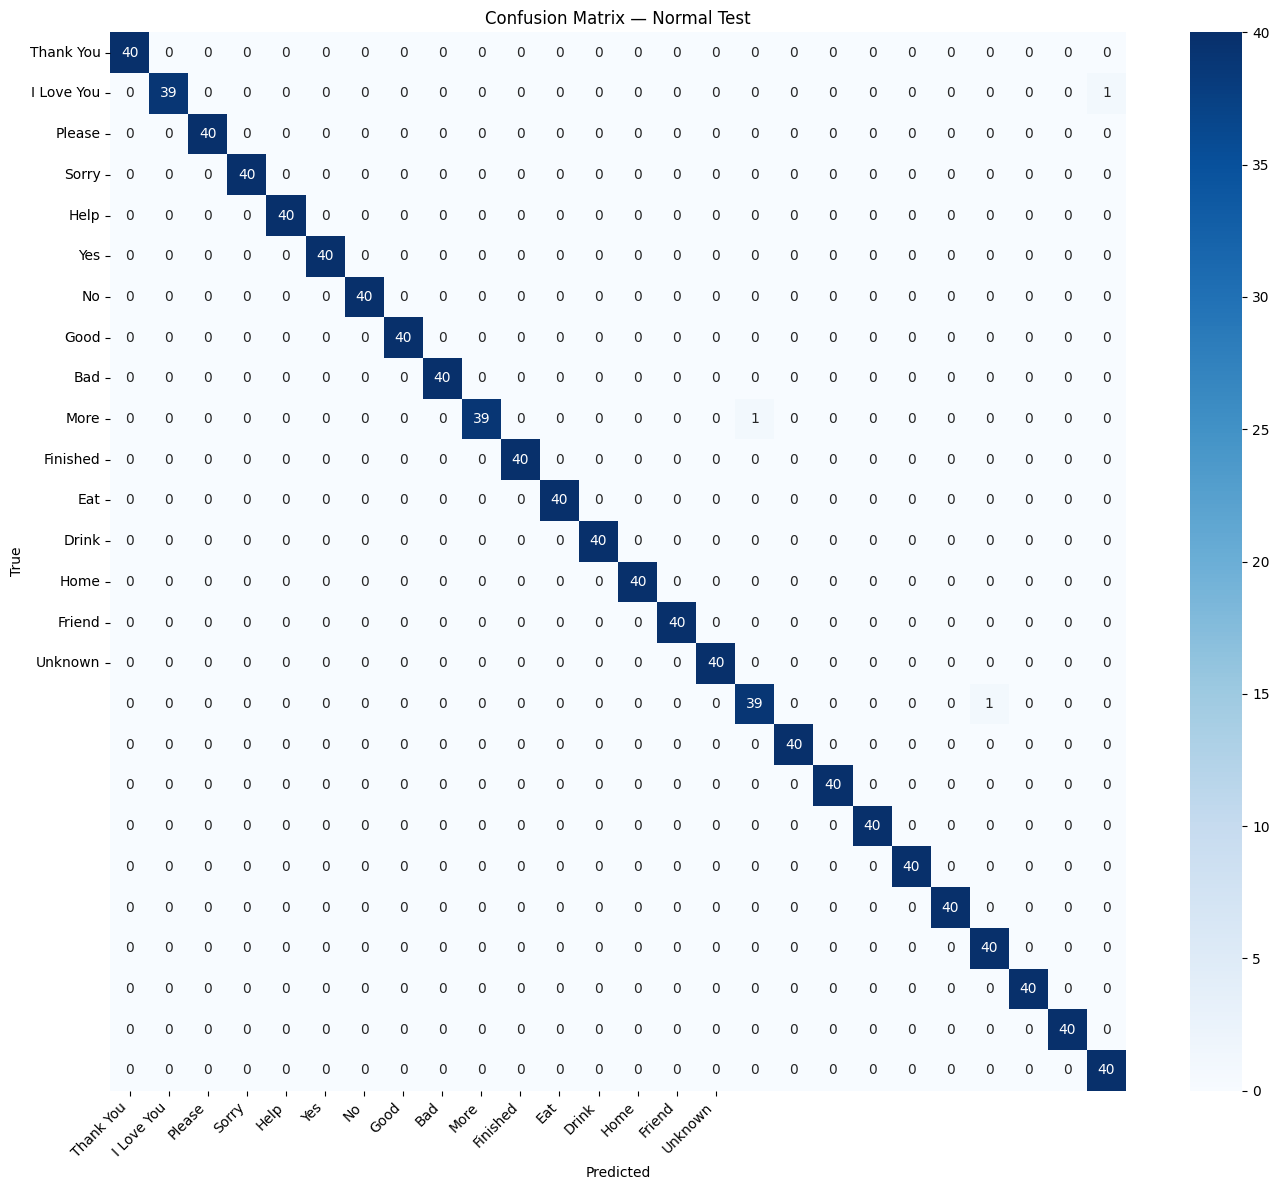

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from time import time
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, mean_squared_error
import numpy as np
from time import time
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, mean_squared_error
import numpy as np

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

# Latency
times_normal = []
for x in X_test:
    t0 = time()
    model(x.reshape(1, -1))
    times_normal.append((time() - t0) * 1000)

acc = accuracy_score(y_true, y_pred)
rec = recall_score(y_true, y_pred, average='macro')
f1  = f1_score(y_true, y_pred, average='macro')
mse = mean_squared_error(y_true, y_pred)

print("=== NORMAL INPUT TEST ===")
print(f"Accuracy : {acc:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1       : {f1:.4f}")
print(f"MSE      : {mse:.4f}")
print(f"Latency  — Avg: {np.mean(times_normal):.3f} ms | Min: {np.min(times_normal):.3f} ms | Max: {np.max(times_normal):.3f} ms | p95: {np.percentile(times_normal, 95):.3f} ms")

# Confusion Matrix
PHRASE_CLASSES = [
    "Thank You", "I Love You", "Please", "Sorry", "Help",
    "Yes", "No", "Good", "Bad", "More",
    "Finished", "Eat", "Drink", "Home", "Friend", "Unknown"
]

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=PHRASE_CLASSES,
            yticklabels=PHRASE_CLASSES)
plt.title("Confusion Matrix — Normal Test")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [14]:
# EDGE CASE 1 — Incomplete Landmark Input
# Simulates one hand partially outside frame / detection failure
# Zeros out 20% of the 128 features

def occlude_features(X, percent=0.2):
    X_mod    = X.copy()
    n_feat   = X.shape[1]
    n_remove = int(n_feat * percent)
    for i in range(len(X_mod)):
        idx = np.random.choice(n_feat, n_remove, replace=False)
        X_mod[i, idx] = 0
    return X_mod

X_test_occ = occlude_features(X_test, 0.2)

times_occ = []
for x in X_test_occ:
    t0 = time()
    model(x.reshape(1, -1))
    times_occ.append((time() - t0) * 1000)

y_pred_occ = np.argmax(model.predict(X_test_occ), axis=1)

print("=== EDGE CASE 1 — Incomplete Landmark Input ===")
print(f"Accuracy : {accuracy_score(y_true, y_pred_occ):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred_occ, average='macro'):.4f}")
print(f"F1       : {f1_score(y_true, y_pred_occ, average='macro'):.4f}")
print(f"Latency  — Avg: {np.mean(times_occ):.3f} ms | Min: {np.min(times_occ):.3f} ms | Max: {np.max(times_occ):.3f} ms | p95: {np.percentile(times_occ, 95):.3f} ms")


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
=== EDGE CASE 1 — Incomplete Landmark Input ===
Accuracy : 0.9442
Recall   : 0.9442
F1       : 0.9449
Latency  — Avg: 3.818 ms | Min: 3.583 ms | Max: 8.474 ms | p95: 4.385 ms


In [15]:
# EDGE CASE 2 — Noisy Landmarks
# Simulates shaky hands / tracking jitter across both hands

def add_noise(X, scale=0.02):
    return X + np.random.normal(0, scale, X.shape)

X_test_noise = add_noise(X_test, 0.02)

times_noise = []
for x in X_test_noise:
    t0 = time()
    model(x.reshape(1, -1))
    times_noise.append((time() - t0) * 1000)

y_pred_noise = np.argmax(model.predict(X_test_noise), axis=1)

print("=== EDGE CASE 2 — Landmark Noise Stability ===")
print(f"Accuracy : {accuracy_score(y_true, y_pred_noise):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred_noise, average='macro'):.4f}")
print(f"F1       : {f1_score(y_true, y_pred_noise, average='macro'):.4f}")
print(f"Latency  — Avg: {np.mean(times_noise):.3f} ms | Min: {np.min(times_noise):.3f} ms | Max: {np.max(times_noise):.3f} ms | p95: {np.percentile(times_noise, 95):.3f} ms")


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
=== EDGE CASE 2 — Landmark Noise Stability ===
Accuracy : 0.9923
Recall   : 0.9923
F1       : 0.9923
Latency  — Avg: 3.857 ms | Min: 3.677 ms | Max: 16.722 ms | p95: 4.198 ms


In [16]:
# EDGE CASE 3 — Latency Comparison Table
print("=== EDGE CASE 3 — Latency Summary ===")
print(f"{'Test':<30} {'Avg (ms)':>10} {'Min (ms)':>10} {'Max (ms)':>10} {'p95 (ms)':>10}")
print("-" * 65)
for label, times in [
    ("Normal Input",        times_normal),
    ("Incomplete Landmark", times_occ),
    ("Landmark Noise",      times_noise),
]:
    t = np.array(times)
    print(f"{label:<30} {np.mean(t):>10.3f} {np.min(t):>10.3f} {np.max(t):>10.3f} {np.percentile(t,95):>10.3f}")


=== EDGE CASE 3 — Latency Summary ===
Test                             Avg (ms)   Min (ms)   Max (ms)   p95 (ms)
-----------------------------------------------------------------
Normal Input                        3.796      3.573     33.019      4.233
Incomplete Landmark                 3.818      3.583      8.474      4.385
Landmark Noise                      3.857      3.677     16.722      4.198


# Model Export

In [17]:
model.export("phrase_saved_model")
print("SavedModel export complete!")

import json
with open("phrase_labels.json", "w", encoding="utf-8") as f:
    json.dump(PHRASE_CLASSES, f, ensure_ascii=False, indent=2)
print(f"Saved phrase_labels.json with {len(PHRASE_CLASSES)} labels in model output order")


INFO:tensorflow:Assets written to: phrase_saved_model/assets


INFO:tensorflow:Assets written to: phrase_saved_model/assets


Saved artifact at 'phrase_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 26), dtype=tf.float32, name=None)
Captures:
  126126920813264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920815376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920816336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920815952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920814032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920815760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920816528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126126920814224: TensorSpec(shape=(), dtype=tf.resource, name=None)
SavedModel export complete!
Saved phrase_labels.json with 16 labels in model output order


In [ ]:
# Convert to TFJS (run in Google Colab if needed)
# !tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model phrase_saved_model phrase_tfjs_model


In [ ]:
import tensorflow as tf

converter = tf.lite.TFLiteConverter.from_saved_model("phrase_saved_model")
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("phrase_model.tflite", "wb") as f:
    f.write(tflite_model)

print("TFLite model saved!")


# Edge Case Testing — Live Camera (Two Hands)

Same structure as the letter model tests. Each test streams the camera inline.

### Controls
| Key | Action |
|-----|--------|
| 💾 Save Frame | Log current frame result |
| ⏹ Quit | Stop test and print summary |

> Run the **Shared Setup** cell first, then run any test independently.


In [18]:
import cv2
import mediapipe as mp
import numpy as np
import csv
import os
import threading
import ipywidgets as widgets
from IPython.display import display
from time import time
from datetime import datetime
import tensorflow as tf

# Load exactly the label order used during model training/export.
with open("phrase_labels.json", encoding="utf-8") as f:
    PHRASE_CLASSES = json.load(f)
CONFIDENCE_THRESHOLD = 0.85
CENTER_BY_WRIST      = True

# Load model
model_loaded = tf.saved_model.load("phrase_saved_model")
infer        = model_loaded.signatures["serving_default"]
input_key    = list(infer.structured_input_signature[1].keys())[0]
print(f"Model loaded. Input key: {input_key}")

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils

def extract_two_hand_keypoints_live(result):
    left_pts  = np.zeros(64)
    right_pts = np.zeros(64)
    if result.multi_hand_landmarks:
        for lm, hd in zip(result.multi_hand_landmarks, result.multi_handedness):
            label = hd.classification[0].label
            pts   = np.array([[p.x, p.y, p.z] for p in lm.landmark])
            if CENTER_BY_WRIST:
                pts -= pts[0]
            pts_flat = np.append(pts.flatten(), 0 if label == "Left" else 1)
            if label == "Left":
                left_pts  = pts_flat
            else:
                right_pts = pts_flat
    return np.concatenate([left_pts, right_pts])

def extract_keypoints_two_hands(frame, hands_model):
    rgb    = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands_model.process(rgb)
    hands_found = 0
    if result.multi_hand_landmarks:
        hands_found = len(result.multi_hand_landmarks)
        for lm in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, lm, mp_hands.HAND_CONNECTIONS)
    kp = extract_two_hand_keypoints_live(result)
    return kp, frame, hands_found

def run_inference(keypoints):
    x      = tf.convert_to_tensor(keypoints.reshape(1, -1), dtype=tf.float32)
    t0     = time()
    out    = infer(**{input_key: x})
    probs  = list(out.values())[0].numpy()[0]
    lat_ms = (time() - t0) * 1000
    idx        = int(np.argmax(probs))
    confidence = float(probs[idx])
    label      = PHRASE_CLASSES[idx] if confidence >= CONFIDENCE_THRESHOLD else "Unknown"
    return label, confidence, lat_ms

def save_csv(log, filename):
    if not log:
        return
    with open(filename, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=log[0].keys())
        writer.writeheader()
        writer.writerows(log)
    print(f"  Saved → {filename}")

def print_summary(log, test_name):
    if not log:
        print("  No frames recorded.")
        return
    latencies = [r["latency_ms"] for r in log]
    valid_lat = [l for l in latencies if l > 0]
    unknown   = sum(1 for r in log if r["predicted_label"] in ("Unknown", "N/A — no hands", "—"))
    print(f"\n{'='*55}")
    print(f"  {test_name} — Summary")
    print(f"{'='*55}")
    print(f"  Frames recorded    : {len(log)}")
    print(f"  Unknown/low conf   : {unknown} / {len(log)}")
    if valid_lat:
        print(f"  --- Latency (ms) ---")
        print(f"  Avg : {np.mean(valid_lat):.3f}")
        print(f"  Min : {np.min(valid_lat):.3f}")
        print(f"  Max : {np.max(valid_lat):.3f}")
        print(f"  p95 : {np.percentile(valid_lat, 95):.3f}")
    print(f"{'='*55}\n")

def draw_hud(frame, lines, colors):
    for i, (text, color) in enumerate(zip(lines, colors)):
        cv2.putText(frame, text, (10, 30 + i*30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

def encode_frame(frame):
    _, buf = cv2.imencode(".jpg", frame, [cv2.IMWRITE_JPEG_QUALITY, 80])
    return bytes(buf)

print("Shared setup ready. ✓")


Model loaded. Input key: keras_tensor
Shared setup ready. ✓


---
## Test 1 — Normal Input
**What it tests:** Full two-hand pipeline with a phrase from the dataset.  
**Expected:** Correct phrase predicted, confidence ≥ 85 %, low latency.  
**Controls:** Show a phrase sign · **[Save Frame]** to log · **[Quit]** to stop.


In [20]:
TEST_NAME = "Test 1 — Normal Input"
LOG_FILE  = "phrase_test1_normal.csv"
log       = []
_running  = [True]

img_out    = widgets.Image(format="jpeg", width=640, height=480)
status_out = widgets.Output()
btn_save   = widgets.Button(description="💾 Save Frame", button_style="success")
btn_quit   = widgets.Button(description="⏹ Quit",        button_style="danger")

display(widgets.VBox([
    widgets.HTML(f"<h3>{TEST_NAME}</h3>"),
    img_out,
    widgets.HBox([btn_save, btn_quit]),
    status_out
]))

def on_quit(b):
    _running[0] = False
btn_quit.on_click(on_quit)

_last = {"label": "—", "conf": 0.0, "lat_ms": 0.0, "total_ms": 0.0, "hands": 0}

def on_save(b):
    entry = {
        "timestamp":       datetime.now().isoformat(),
        "test":            TEST_NAME,
        "hands_detected":  _last["hands"],
        "predicted_label": _last["label"],
        "confidence":      round(_last["conf"], 4),
        "latency_ms":      round(_last["lat_ms"], 3),
        "total_frame_ms":  round(_last["total_ms"], 3),
    }
    log.append(entry)
    with status_out:
        print(f"  Saved: {_last['label']} ({_last['conf']*100:.1f}%) — {_last['lat_ms']:.2f} ms  [{_last['hands']} hand(s)]")
btn_save.on_click(on_save)

def camera_loop():
    hands_model = mp_hands.Hands(static_image_mode=False, max_num_hands=2,
                                 min_detection_confidence=0.7, min_tracking_confidence=0.7)
    cap = cv2.VideoCapture(0)
    while _running[0]:
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.flip(frame, 1)
        t0    = time()

        kp, frame, hands_found = extract_keypoints_two_hands(frame, hands_model)
        label, conf, lat_ms    = "—", 0.0, 0.0

        if hands_found > 0:
            label, conf, lat_ms = run_inference(kp)

        total_ms = (time() - t0) * 1000
        _last.update({"label": label, "conf": conf, "lat_ms": lat_ms,
                      "total_ms": total_ms, "hands": hands_found})

        color = (0,255,0) if conf >= CONFIDENCE_THRESHOLD else (0,165,255)
        draw_hud(frame,
            [f"Pred  : {label}", f"Conf  : {conf*100:.1f}%",
             f"Hands : {hands_found}", f"Lat   : {lat_ms:.1f} ms",
             f"Total : {total_ms:.1f} ms", "Click [Save Frame] or [Quit]"],
            [color, color, (255,255,0), (255,255,255), (200,200,200), (180,180,180)])

        img_out.value = encode_frame(frame)

    cap.release()
    hands_model.close()
    if log:
        save_csv(log, LOG_FILE)
    print_summary(log, TEST_NAME)

threading.Thread(target=camera_loop, daemon=True).start()


I0000 00:00:1791735467.560487   22045 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1791735467.562788   22056 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.0.7-0ubuntu0.24.04.2), renderer: Mesa Intel(R) UHD Graphics 620 (WHL GT2)
W0000 00:00:1791735467.575368   22046 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791735467.596310   22051 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
Exception in thread Thread-7 (camera_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1073, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1010, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_9821/3091116168.py", line 54, in camera_loop
  File "/tmp/i

---
## Test 2 — No Input (Empty Frame)
**What it tests:** Pipeline behaviour when no hands are in frame.  
**Expected:** Model is never called, no crash, graceful handling.  
**Controls:** Keep hands OUT of frame · **[Save Frame]** to log · **[Quit]** to stop.


In [ ]:
TEST_NAME = "Test 2 — No Input"
LOG_FILE  = "phrase_test2_no_input.csv"
log       = []
_running  = [True]

img_out    = widgets.Image(format="jpeg", width=640, height=480)
status_out = widgets.Output()
btn_save   = widgets.Button(description="💾 Save Frame", button_style="success")
btn_quit   = widgets.Button(description="⏹ Quit",        button_style="danger")

display(widgets.VBox([
    widgets.HTML(f"<h3>{TEST_NAME}</h3>"),
    img_out,
    widgets.HBox([btn_save, btn_quit]),
    status_out
]))

def on_quit(b):
    _running[0] = False
btn_quit.on_click(on_quit)

_last = {"hands": 0, "total_ms": 0.0}

def on_save(b):
    entry = {
        "timestamp":       datetime.now().isoformat(),
        "test":            TEST_NAME,
        "hands_detected":  _last["hands"],
        "predicted_label": "N/A — no hands" if _last["hands"] == 0 else "Hands detected!",
        "confidence":      0.0,
        "latency_ms":      0.0,
        "total_frame_ms":  round(_last["total_ms"], 3),
    }
    log.append(entry)
    with status_out:
        status = f"No hands ({_last['total_ms']:.2f} ms)" if _last["hands"] == 0 else f"⚠ {_last['hands']} hand(s) detected!"
        print(f"  Saved: {status}")
btn_save.on_click(on_save)

def camera_loop():
    hands_model = mp_hands.Hands(static_image_mode=False, max_num_hands=2,
                                 min_detection_confidence=0.7, min_tracking_confidence=0.7)
    cap = cv2.VideoCapture(0)
    while _running[0]:
        ret, frame = cap.read()
        if not ret:
            continue
        frame    = cv2.flip(frame, 1)
        t0       = time()
        _, frame, hands_found = extract_keypoints_two_hands(frame, hands_model)
        total_ms = (time() - t0) * 1000
        _last.update({"hands": hands_found, "total_ms": total_ms})

        status = f"⚠ {hands_found} hand(s) detected!" if hands_found > 0 else "No hands detected"
        color  = (0,0,255) if hands_found > 0 else (0,200,255)
        draw_hud(frame,
            [status, f"Total: {total_ms:.1f} ms", "Click [Save Frame] or [Quit]"],
            [color, (200,200,200), (180,180,180)])

        img_out.value = encode_frame(frame)

    cap.release()
    hands_model.close()
    if log:
        save_csv(log, LOG_FILE)
    print_summary(log, TEST_NAME)

threading.Thread(target=camera_loop, daemon=True).start()


---
## Test 3 — Unknown / Out-of-Distribution Input
**What it tests:** Model behaviour on signs NOT in the dataset.  
**Expected:** Confidence < 85 % → flagged "Unknown". High confidence on wrong label = lower threshold needed.  
**Controls:** Show signs NOT in dataset · **[Save Frame]** to log · **[Quit]** to stop.


In [ ]:
TEST_NAME = "Test 3 — Unknown Input"
LOG_FILE  = "phrase_test3_unknown.csv"
log       = []
_running  = [True]

img_out    = widgets.Image(format="jpeg", width=640, height=480)
status_out = widgets.Output()
btn_save   = widgets.Button(description="💾 Save Frame", button_style="success")
btn_quit   = widgets.Button(description="⏹ Quit",        button_style="danger")

display(widgets.VBox([
    widgets.HTML(f"<h3>{TEST_NAME}</h3>"),
    img_out,
    widgets.HBox([btn_save, btn_quit]),
    status_out
]))

def on_quit(b):
    _running[0] = False
btn_quit.on_click(on_quit)

_last = {"raw": "—", "label": "—", "conf": 0.0,
         "lat_ms": 0.0, "total_ms": 0.0, "hands": 0}

def on_save(b):
    entry = {
        "timestamp":           datetime.now().isoformat(),
        "test":                TEST_NAME,
        "hands_detected":      _last["hands"],
        "raw_predicted_label": _last["raw"],
        "predicted_label":     _last["label"],
        "confidence":          round(_last["conf"], 4),
        "confidently_wrong":   _last["hands"] > 0 and _last["label"] != "Unknown",
        "latency_ms":          round(_last["lat_ms"], 3),
        "total_frame_ms":      round(_last["total_ms"], 3),
    }
    log.append(entry)
    with status_out:
        flag = "⚠ CONFIDENTLY WRONG" if entry["confidently_wrong"] else "✓ Unknown"
        print(f"  Saved: raw={_last['raw']} → {_last['label']} ({_last['conf']*100:.1f}%) {flag} — {_last['lat_ms']:.2f} ms")
btn_save.on_click(on_save)

def camera_loop():
    hands_model = mp_hands.Hands(static_image_mode=False, max_num_hands=2,
                                 min_detection_confidence=0.7, min_tracking_confidence=0.7)
    cap = cv2.VideoCapture(0)
    while _running[0]:
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.flip(frame, 1)
        t0    = time()

        kp, frame, hands_found = extract_keypoints_two_hands(frame, hands_model)
        raw_label, label, conf, lat_ms = "—", "—", 0.0, 0.0

        if hands_found > 0:
            x      = tf.convert_to_tensor(kp.reshape(1,-1), dtype=tf.float32)
            ti     = time()
            out    = infer(**{input_key: x})
            probs  = list(out.values())[0].numpy()[0]
            lat_ms = (time() - ti) * 1000
            idx       = int(np.argmax(probs))
            conf      = float(probs[idx])
            raw_label = PHRASE_CLASSES[idx]
            label     = raw_label if conf >= CONFIDENCE_THRESHOLD else "Unknown"

        total_ms = (time() - t0) * 1000
        _last.update({"raw": raw_label, "label": label, "conf": conf,
                      "lat_ms": lat_ms, "total_ms": total_ms, "hands": hands_found})

        is_safe = (label == "Unknown" or hands_found == 0)
        color   = (0,255,0) if is_safe else (0,0,255)
        draw_hud(frame,
            [f"Raw   : {raw_label}", f"Result: {label}",
             f"Conf  : {conf*100:.1f}%", f"Hands : {hands_found}",
             f"Lat   : {lat_ms:.1f} ms", f"Total : {total_ms:.1f} ms",
             "Click [Save Frame] or [Quit]"],
            [(200,200,200), color, color, (255,255,0),
             (255,255,255), (200,200,200), (180,180,180)])

        img_out.value = encode_frame(frame)

    cap.release()
    hands_model.close()
    if log:
        save_csv(log, LOG_FILE)
    confidently_wrong = [r for r in log if r.get("confidently_wrong")]
    print_summary(log, TEST_NAME)
    if confidently_wrong:
        print(f"  ⚠  CONFIDENTLY WRONG frames : {len(confidently_wrong)}")
        print(f"     Lower CONFIDENCE_THRESHOLD or add more Unknown samples.")
    elif log:
        print(f"  ✓  All unknown gestures correctly flagged.")

threading.Thread(target=camera_loop, daemon=True).start()


---
## Combined Results Summary
Run after completing all three tests.

In [ ]:
import csv
import numpy as np
import os

files = {
    "Test 1 — Normal Input":  "phrase_test1_normal.csv",
    "Test 2 — No Input":      "phrase_test2_no_input.csv",
    "Test 3 — Unknown Input": "phrase_test3_unknown.csv",
}

print(f"{'Test':<28} {'Frames':>7} {'Detected':>9} {'Unknown':>9} {'Avg ms':>8} {'Max ms':>8} {'p95 ms':>8}")
print("-" * 82)

for name, path in files.items():
    if not os.path.exists(path):
        print(f"{name:<28}  — file not found, skip")
        continue
    with open(path) as f:
        rows = list(csv.DictReader(f))
    if not rows:
        print(f"{name:<28}  — empty log")
        continue

    latencies = [float(r["latency_ms"]) for r in rows]
    detected  = sum(1 for r in rows if int(r.get("hands_detected", 0)) > 0)
    unknown   = sum(1 for r in rows if r["predicted_label"] in ("Unknown", "N/A — no hands", "—"))
    valid_lat = [l for l in latencies if l > 0]
    avg = np.mean(valid_lat) if valid_lat else 0
    mx  = np.max(valid_lat)  if valid_lat else 0
    p95 = np.percentile(valid_lat, 95) if valid_lat else 0

    print(f"{name:<28} {len(rows):>7} {detected:>9} {unknown:>9} {avg:>8.2f} {mx:>8.2f} {p95:>8.2f}")

print("-" * 82)
print("Latency = model inference only (ms). Total frame time includes MediaPipe.")


## Final Camera Test — Live Predictions and Unknown Detection

Run this **after training and exporting** your model. This test opens a local OpenCV camera window and shows the raw prediction, confidence, final displayed result, and top 3 classes.

- **Q**: quit the camera test.
- **S**: save the current prediction to a CSV file.
- Change `CAMERA_INDEX` if your webcam is not camera 0.
- Change `REJECTION_THRESHOLD` to experiment with low-confidence rejection.

**Important:** The `Unknown` class must have real, diverse training samples. A confidence threshold cannot reliably reject unfamiliar gestures that receive high softmax confidence. The display deliberately shows both the raw class and final decision so you can diagnose this.


In [ ]:
# FINAL LIVE CAMERA TEST (local Jupyter / desktop Python)
import cv2
import numpy as np
import tensorflow as tf
import mediapipe as mp
import csv
from pathlib import Path
from datetime import datetime
from time import perf_counter

CAMERA_INDEX = 0
REJECTION_THRESHOLD = 0.85
MODEL_DIR = "phrase_saved_model"
LOG_PATH = "phrase_final_camera_test.csv"

# Use the exact class order from training.
with open("phrase_labels.json", encoding="utf-8") as f:
    class_names = json.load(f)
assert "Unknown" in class_names, "Unknown is missing from PHRASE_CLASSES."

# Prefer the freshly trained in-memory model; otherwise load the exported SavedModel.
if "model" in globals() and isinstance(model, tf.keras.Model):
    def predict_probs(features):
        return np.asarray(model(features, training=False))[0]
    print("Using in-memory Keras model.")
else:
    saved = tf.saved_model.load(MODEL_DIR)
    signature = saved.signatures["serving_default"]
    input_name = next(iter(signature.structured_input_signature[1]))
    def predict_probs(features):
        outputs = signature(**{input_name: tf.convert_to_tensor(features, dtype=tf.float32)})
        return np.asarray(next(iter(outputs.values())))[0]
    print(f"Using exported model: {MODEL_DIR}")

# Same extraction as training: left 64 + right 64, wrist-relative.
def camera_features(results):
    left = np.zeros(64, dtype=np.float32)
    right = np.zeros(64, dtype=np.float32)
    if results.multi_hand_landmarks:
        for lm, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):
            side = handedness.classification[0].label
            points = np.array([[p.x, p.y, p.z] for p in lm.landmark], dtype=np.float32)
            if CENTER_BY_WRIST:
                points -= points[0]
            packed = np.append(points.flatten(), 0 if side == "Left" else 1).astype(np.float32)
            if side == "Left":
                left = packed
            else:
                right = packed
    return np.concatenate([left, right])[None, :]

cap = cv2.VideoCapture(CAMERA_INDEX)
if not cap.isOpened():
    raise RuntimeError(f"Could not open camera {CAMERA_INDEX}. Close other camera apps or change CAMERA_INDEX.")

rows = []
window_name = "AuriSign - Final Phrase Camera Test"
hands_api = mp.solutions.hands
drawing = mp.solutions.drawing_utils
try:
    with hands_api.Hands(static_image_mode=False, max_num_hands=2,
                         min_detection_confidence=0.7,
                         min_tracking_confidence=0.7) as tracker:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("Camera frame unavailable; ending test.")
                break
            frame = cv2.flip(frame, 1)
            result = tracker.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            count = len(result.multi_hand_landmarks or [])
            raw_label, shown_label, confidence = "No hands", "No hands detected", 0.0
            top3 = []
            latency_ms = 0.0
            if count:
                for hand in result.multi_hand_landmarks:
                    drawing.draw_landmarks(frame, hand, hands_api.HAND_CONNECTIONS)
                features = camera_features(result)
                start = perf_counter()
                probabilities = predict_probs(features)
                latency_ms = (perf_counter() - start) * 1000
                if len(probabilities) != len(class_names):
                    raise ValueError(f"Model has {len(probabilities)} outputs but {len(class_names)} labels. Retrain/export with matching class order.")
                order = np.argsort(probabilities)[::-1]
                index = int(order[0])
                raw_label = class_names[index]
                confidence = float(probabilities[index])
                shown_label = "Unknown" if raw_label == "Unknown" or confidence < REJECTION_THRESHOLD else raw_label
                top3 = [(class_names[int(i)], float(probabilities[i])) for i in order[:3]]
            lines = [
                f"Raw prediction: {raw_label}",
                f"Displayed result: {shown_label}",
                f"Confidence: {confidence:.1%}  |  Threshold: {REJECTION_THRESHOLD:.0%}",
                f"Hands detected: {count}  |  Inference: {latency_ms:.1f} ms",
            ]
            lines += [f"Top {j}: {name} ({score:.1%})" for j, (name, score) in enumerate(top3, 1)]
            lines.append("S: save result    Q: quit")
            for j, line in enumerate(lines):
                color = (0, 255, 255) if j == 1 and shown_label == "Unknown" else (255, 255, 255)
                cv2.putText(frame, line, (12, 30 + 29*j), cv2.FONT_HERSHEY_SIMPLEX,
                            0.62, (0, 0, 0), 4, cv2.LINE_AA)
                cv2.putText(frame, line, (12, 30 + 29*j), cv2.FONT_HERSHEY_SIMPLEX,
                            0.62, color, 2, cv2.LINE_AA)
            cv2.imshow(window_name, frame)
            key = cv2.waitKey(1) & 0xFF
            if key == ord("s"):
                rows.append({
                    "timestamp": datetime.now().isoformat(timespec="seconds"),
                    "hands_detected": count,
                    "raw_prediction": raw_label,
                    "displayed_result": shown_label,
                    "confidence": round(confidence, 5),
                    "latency_ms": round(latency_ms, 2),
                    "top_3": "; ".join(f"{name}: {score:.3f}" for name, score in top3),
                })
                print(f"Saved: {shown_label} (raw={raw_label}, confidence={confidence:.1%})")
            elif key == ord("q"):
                break
finally:
    cap.release()
    cv2.destroyAllWindows()
    if rows:
        with open(LOG_PATH, "w", newline="", encoding="utf-8") as file:
            writer = csv.DictWriter(file, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
        print(f"Saved {len(rows)} results to {LOG_PATH}")
    print("Camera test finished.")
